# Full 3 validation — `channel_full3_ptov / dainty-sunset-0`

Load the run's best validation checkpoint (`ckpt_best.pt`, epoch 19 **zero-based**) and regenerate velocity predictions from lower-wall pressure. Compare with the independent `re200-sr1etot` validation run, on the lower half through the centerline. This is **validation**, not an unbiased test score: validation selected the checkpoint. No raw predictions were found next to the checkpoint. This notebook does not train or write to S3.

Run from the project root or `networks/full` with the project Python environment and read access to its S3 endpoint. Start with `RUN_LIVE = False`; the large data read is opt-in. The checkpoint has no saved normalization values: reconstruct them from its exact A1 training slice `[200:3196:1]` (2,996 snapshots) using the trainer's per-channel sample standard deviation. Validation `[200:1001:1]` uses all 801 snapshots including the final short batch. To preview, change `VALIDATION_LIMIT`; this does not reduce the training normalization read. `NORMALIZATION` can be set to previously computed stats from the *same* training selection to avoid that read.

Full S3 reads from the verified compressed chunk inventory: **107.31 GB** for normalization, **28.69 GB** for validation plus **28.69 GB** for the optional exact PDFs. One chunk per selected snapshot per pass; about **164.68 GB** in total when PDFs are enabled. Fields stream in bounded batches; only reductions are retained. Sources: `full_3.ipynb`, `train_channel.py`, `../couette_predi/couette_predi_eval.ipynb`, and the checkpoint's saved config.

In [1]:
from pathlib import Path
from io import BytesIO
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

for root in (Path.cwd(), Path.cwd() / 'networks' / 'full'):
    if (root / 'train_channel.py').is_file():
        sys.path.insert(0, str(root))
        break
else:
    raise FileNotFoundError('Start the kernel from the project root or networks/full')

from train_channel import _s3fs, _open_data_zarr, _open_channel_axis, make_model

COMPONENTS = ('u', 'v', 'w')
STRESS_PAIRS = ((0, 1, 'u′v′'), (0, 2, 'u′w′'), (1, 2, 'v′w′'))
CHECKPOINT = 'models/channel-1/channel_full3_ptov/dainty-sunset-0/ckpt_best.pt'
TRAIN_ROOT = 'flow_export/A1'
VAL_ROOT = 'validation/re200-sr1etot'

In [2]:
def read_batch(a, s, ny, stride):
    # Match the full_3 mapping: u,v,w = fields 0–2; p = field 3 at the lower wall.
    # One Zarr read, since each snapshot's fields share a chunk in both stores.
    f = np.asarray(a[s, :4, ::stride, :ny, ::stride], dtype=np.float32)
    return np.ascontiguousarray(f[:, 3:4, :, :1, :]), np.ascontiguousarray(f[:, :3])


def selections(r, batch_size):
    if batch_size < 1 or r.step < 1 or not len(r):
        raise ValueError('Need a nonempty forward selection and positive batch size')
    for i in range(0, len(r), batch_size):
        b = r[i:i + batch_size]
        yield slice(b.start, b.stop, b.step)


def training_norm(a, r, ny, stride, batch_size, progress=False):
    # Parallel-variance merge; equivalent to train_channel._channel_stats (ddof=1).
    counts = [0, 0]
    means = [0., 0.]
    m2s = [0., 0.]
    for s in tqdm(selections(r, batch_size), total=(len(r)+batch_size-1)//batch_size,
                  desc='A1 normalization', disable=not progress):
        for j, v in enumerate(read_batch(a, s, ny, stride)):
            if not np.isfinite(v).all():
                raise ValueError(f'Nonfinite training field in {s}')
            dims = (0, 2, 3, 4)
            n = v.size // v.shape[1]
            mean = np.mean(v, axis=dims, dtype=np.float64)
            m2 = np.var(v, axis=dims, dtype=np.float64) * n
            delta = mean - means[j]
            total = counts[j] + n
            m2s[j] = m2s[j] + m2 + delta**2 * (counts[j] * n / total)
            means[j] = means[j] + delta * (n / total)
            counts[j] = total
    def pack(v):
        return np.asarray(v, dtype=np.float32)[None, :, None, None, None]
    return tuple(v for j in range(2) for v in
                 (pack(means[j]), pack(np.sqrt(m2s[j]/(counts[j]-1))).clip(min=1e-6)))


def prediction_batches(a, r, ny, stride, batch_size, model, norm, device, progress=False):
    xm, xs, ym, ys = (torch.as_tensor(q, dtype=torch.float32, device=device) for q in norm)
    for s in tqdm(selections(r, batch_size), total=(len(r)+batch_size-1)//batch_size,
                  desc='Validation inference', disable=not progress):
        x, target = read_batch(a, s, ny, stride)
        with torch.inference_mode():
            prediction = model((torch.from_numpy(x).to(device) - xm) / xs)
            physical = (prediction * ys + ym).cpu().numpy()
        yield physical, target

## Metrics and wall layers

- **Pointwise comparison:** global and component MSE; plane-wise MSE, mean and population standard deviation (fluctuation RMS) versus distance from the measured wall; three Reynolds shear stress profiles; fluctuation PDFs for all evaluated planes and one buffer-layer plane, with buffer-plane skewness and excess kurtosis. Profiles and stresses pool snapshots and x/z points; stress is a mean, not the unnormalized sum in the Couette notebook. No interpolation or wall folding.
- **Spectra:** full x–z FFT using the sampled grid and periodic lengths $L_x=N_x\Delta x$ and $L_z=N_z\Delta z$ (verified **12.57** and **4.19**). Use physical radial wavenumber $|k|$, with annuli centered on multiples of $\Delta k=\min(2\pi/L_x,2\pi/L_z)$, half-bin edges, and the zero mode reported separately. Each plane and snapshot has equal weight within its layer, matching Couette's sample pooling on a nonuniform y grid (not a wall-normal volume integral).
- **Two spectral errors:** squared *power* mismatch, as in the Couette eval, averaged over modes, planes and snapshots per bin (the legacy sums and relative ratio are also available in `results`); and **paired Fourier MSE** from $|\hat u_{pred}-\hat u_{DNS}|^2$, which retains phase errors. The latter sums to the physical MSE over all bins including DC. Raw-field spectra include the mean; DC is excluded from the radial plots but printed. The paired relative error is separately normalized by DNS power, with near-zero denominators masked.
- **Layer boundaries:** nominal $y^+=(y-y_{wall})Re_\tau/\delta$, using configured $Re_\tau=200$ and grid half-height $\delta=1$. Diagnostics split into viscous sublayer $[0,5)$, buffer layer $[5,30)$, nominal log/overlap band $[30,100)$, and outer/core $[100,\infty)$. `RE_TAU` can be changed if you have a measured value. These boundaries are diagnostic bins, not a claim of a developed log law at this Reynolds number. See the project `validation.md` for the near-wall and nominal log ranges.

In [3]:
def fft_grid(nx, nz, lx, lz):
    kx = 2*np.pi*np.fft.fftfreq(nx, d=lx/nx)
    kz = 2*np.pi*np.fft.fftfreq(nz, d=lz/nz)
    dk = min(2*np.pi/lx, 2*np.pi/lz)
    r = np.hypot(kx[:, None], kz[None, :])
    bins = np.maximum(1, np.floor(r/dk + .5).astype(int))
    bins[0, 0] = 0
    count = np.bincount(bins.ravel())
    return dict(bins=bins.ravel(), count=count, k=np.arange(count.size)*dk,
                dk=dk, nx=nx, nz=nz)


def relative(numer, denom):
    scale = denom.max(axis=-1, keepdims=True)
    return np.divide(numer, denom, out=np.full_like(numer, np.nan),
                     where=denom > np.maximum(scale*1e-14, 0.0))


def evaluate(factory, grid, masks, pdf_plane, do_pdf=True):
    nx, nz, count = grid['nx'], grid['nz'], grid['count']
    ny = len(next(iter(masks.values())))
    layers = {'all': np.ones(ny, dtype=bool), **masks}
    mse = np.zeros((3, ny)); sum1 = np.zeros((2, 3, ny))
    sum2 = np.zeros((2, 3, 3, ny))
    extrema = np.full_like(sum1, np.inf), np.full_like(sum1, -np.inf)
    # Prediction power, target power, squared power difference, complex residual power.
    bands = {name: np.zeros((4, 3, count.size)) for name, sel in layers.items() if sel.any()}
    snapshots = 0
    for p, t in factory():
        if p.shape != t.shape or p.shape[1:] != (3,nx,ny,nz):
            raise ValueError(f'Unexpected prediction/truth grid: {p.shape}, {t.shape}')
        if not (np.isfinite(p).all() and np.isfinite(t).all()):
            raise ValueError(f'Nonfinite velocity near validation sample {snapshots}')
        p, t = (np.asarray(v, dtype=np.float64) for v in (p,t))
        snapshots += len(t)
        mse += ((p-t)**2).sum(axis=(0,2,4))
        for j, v in enumerate((p,t)):
            sum1[j] += v.sum(axis=(0,2,4))
            sum2[j] += np.einsum('tcxyz,tdxyz->cdy',v,v)
            np.minimum(extrema[0][j], v.min(axis=(0,2,4)), out=extrema[0][j])
            np.maximum(extrema[1][j], v.max(axis=(0,2,4)), out=extrema[1][j])
        for c in range(3):
            f, g = (np.fft.fft2(v[:,c], axes=(1,3))/(nx*nz) for v in (p,t))
            pp, tp = abs(f)**2, abs(g)**2
            for i, power in enumerate((pp, tp, (pp-tp)**2, abs(f-g)**2)):
                per_y = power.sum(axis=0)  # (X,Y,Z)
                for name, out in bands.items():
                    mode = per_y[:,layers[name],:].sum(axis=1)
                    out[i,c] += np.bincount(grid['bins'], weights=mode.ravel(), minlength=count.size)
    if not snapshots:
        raise ValueError('No validation predictions')
    npts = snapshots*nx*nz
    mse /= npts
    means = sum1/npts
    stress = sum2/npts - means[:,:,None,:]*means[:,None,:,:]
    std = np.sqrt(np.maximum(0,np.diagonal(stress, axis1=1, axis2=2).transpose(0,2,1)))
    spectra = {}
    for name,out in bands.items():
        ny_layer = int(layers[name].sum())
        n = snapshots*ny_layer
        pred, dns, sq, paired = out/n
        np.testing.assert_allclose(paired.sum(axis=-1), mse[:,layers[name]].mean(axis=1),
                                   rtol=1e-7, atol=1e-14, err_msg=f'Parseval: {name}')
        spectra[name] = dict(pred=pred, dns=dns, paired=paired, paired_rel=relative(paired,dns),
            power_mse=np.divide(sq,count,out=np.full_like(sq,np.nan),where=count>0),
            power_sq_sum=out[2], planes=ny_layer,
            couette_raw_sum=out[2]*(nx*nz)**2, couette_relative=relative(out[2]*(nx*nz),out[1]))
    result = dict(snapshots=snapshots, mse_y=mse, mse_component=mse.mean(axis=1),
                  mse_global=mse.mean(), mean=means, stress=stress, std=std, spectra=spectra, pdf=None)
    if not do_pdf:
        return result
    # Exactly match the full-data, common symmetric PDF bins; do not store all predictions.
    lo, hi = (v-means for v in extrema)
    limits = np.maximum(abs(lo),abs(hi)).max(axis=0)
    pdf = []
    for ys in (slice(None),pdf_plane):
        entries = []
        for c in range(3):
            lim = float(np.max(limits[c,ys]))*1.05 or 1.0
            entries.append(dict(edges=np.linspace(-lim,lim,120),counts=np.zeros((2,119),dtype=np.int64),
                                shape_sum=np.zeros((2,2))))
        pdf.append(entries)
    n2 = 0
    for p,t in factory():
        n2 += len(t)
        for j,v in enumerate((p,t)):
            for c in range(3):
                for i,ys in enumerate((slice(None),pdf_plane)):
                    d = pdf[i][c]
                    fluc = v[:,c,:,ys,:] - (means[j,c][None,None,:,None] if i==0 else means[j,c,ys])
                    d['counts'][j] += np.histogram(fluc, bins=d['edges'])[0]
                    if i==1:
                        d['shape_sum'][j] += ((fluc**3).sum(), (fluc**4).sum())
    if n2 != snapshots:
        raise ValueError('Validation pass counts differ')
    for i,entries in enumerate(pdf):
        for c,d in enumerate(entries):
            if not np.all(d['counts'].sum(axis=-1)==npts*(ny if i==0 else 1)):
                raise ValueError('PDF histogram lost samples')
            if i==1:
                den = std[:,c,pdf_plane,None] ** np.array([3,4])
                d['shape'] = np.divide(d['shape_sum']/npts,den,out=np.full_like(den,np.nan),where=den>0) - [0,3]
    result['pdf'] = pdf
    return result

In [4]:
def plot_results(m, y, yp, grid, pdf_plane):
    print(f"Validation: {m['snapshots']} snapshots; global physical MSE = {m['mse_global']:.6e}")
    print('Component MSE:', dict(zip(COMPONENTS, m['mse_component'])))
    for metric in ('mean','std','mse_y','stress'):
        fig, axs = plt.subplots(1,3,figsize=(13,3.2),layout='constrained',sharex=True)
        fig.suptitle({'mean':'Mean velocity','std':'Population std / fluctuation RMS',
                      'mse_y':'Physical MSE by measured-wall distance', 'stress':'Reynolds shear stress'}[metric])
        for c, ax in enumerate(axs):
            title = COMPONENTS[c]
            if metric == 'mse_y':
                ax.plot(y,m[metric][c]); ax.set_ylabel('MSE (velocity²)')
            else:
                if metric == 'stress':
                    i,j,title = STRESS_PAIRS[c]; pred,dns = m[metric][:,i,j]
                else:
                    pred,dns = m[metric][:,c]
                ax.plot(y,dns,label='DNS'); ax.plot(y,pred,label='Prediction')
                ax.plot(y,pred-dns,'k--',label='Prediction − DNS'); ax.legend(fontsize=8)
            ax.set(title=title,xlabel='Distance from measured wall'); ax.grid(alpha=.25)
            sec = ax.secondary_xaxis('top',functions=(lambda a:a*yp[-1]/y[-1],lambda a:a*y[-1]/yp[-1]))
            sec.set_xlabel('Nominal y⁺')
        plt.show()
    valid = (grid['count']>0) & (grid['k']>0)
    x = grid['k'][valid]
    specs = m['spectra']
    labels = ('DNS and predicted power', 'Power-spectrum MSE', 'Paired Fourier MSE', 'Paired MSE / DNS power')
    fig, axs = plt.subplots(len(specs),4,figsize=(15,2.7*len(specs)),layout='constrained',squeeze=False)
    for row,(layer,s) in enumerate(specs.items()):
        print(f"{layer}: {s['planes']} planes; DC paired MSE (u,v,w): {s['paired'][:,0]}")
        for col,ax in enumerate(axs[row]):
            for c,(name,color) in enumerate(zip(COMPONENTS,('C0','C1','C2'))):
                if col == 0:
                    ax.semilogy(x,s['dns'][c,valid],color=color,label=f'{name}: DNS')
                    ax.semilogy(x,s['pred'][c,valid],'--',color=color,label=f'{name}: pred')
                else:
                    key = ('power_mse','paired','paired_rel')[col-1]
                    ax.semilogy(x,s[key][c,valid],color=color,label=name)
            ax.set(title=labels[col] if row==0 else '',xlabel='|k| (rad / length)')
            if col==0: ax.set_ylabel(layer)
            if row==0: ax.legend(fontsize=7,ncol=2 if col==0 else 1)
            ax.grid(alpha=.25)
    plt.show()
    if m['pdf'] is not None:
        fig, axs = plt.subplots(3,2,figsize=(11,8),layout='constrained')
        fig.suptitle('Velocity fluctuation PDFs')
        for col,entries in enumerate(m['pdf']):
            for c,d in enumerate(entries):
                ax = axs[c,col]
                for j,name in enumerate(('Prediction','DNS')):
                    h,e = d['counts'][j],d['edges']
                    ax.stairs(h/(h.sum()*np.diff(e)),e,label=name)
                loc = 'all evaluated planes' if col==0 else f'buffer plane y⁺={yp[pdf_plane]:.1f}'
                ax.set(title=f'{COMPONENTS[c]} — {loc}',xlabel='Fluctuation',ylabel='Density'); ax.legend()
                if col==1: print(f"{COMPONENTS[c]} skew, excess kurtosis (prediction / DNS): {d['shape'].tolist()}")
        plt.show()

In [5]:
RUN_LIVE = True  # Opt in after checking the read budget above.
VALIDATION_LIMIT = None  # e.g. 5 selects the first five validation snapshots, never training/test.
EXACT_PDFS = True        # One extra validation pass when enabled.
BATCH_SIZE = 2
NORMALIZATION = None     # Or the exact training (x_mean, x_std, y_mean, y_std) from training_norm.
RE_TAU = 200.0
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

results = None
if RUN_LIVE:
    checkpoint = torch.load(BytesIO(_s3fs().cat_file(CHECKPOINT)),map_location='cpu',weights_only=True)
    cfg = checkpoint['config']
    if (cfg['task'],cfg['wall'],cfg['half_y'],cfg['xz_stride']) != ('wall_pressure_to_velocity','lower',True,1):
        raise ValueError('Checkpoint does not match the evaluation geometry or task')
    model = make_model(cfg['arch'],DEVICE).eval()
    model.load_state_dict(checkpoint['model_state_dict'],strict=True)
    ny, stride = cfg['arch']['dy'], cfg['xz_stride']
    ds = cfg['data_selection']
    tr, vr = (range(*ds[k]['slice']) for k in ('train','validation'))
    assert ds['train']['uri'] == f's3://simulations/{TRAIN_ROOT}/data.zarr'
    assert ds['validation']['uri'] == f's3://simulations/{VAL_ROOT}/data.zarr'
    assert (len(tr),len(vr)) == (ds['train']['snapshots'],ds['validation']['snapshots'])
    if VALIDATION_LIMIT is not None:
        if not 1 <= VALIDATION_LIMIT <= len(vr): raise ValueError('Invalid validation limit')
        vr = vr[:VALIDATION_LIMIT]
    va = _open_data_zarr(VAL_ROOT)
    axes = [_open_channel_axis(VAL_ROOT,a) for a in 'xyz']
    train_axes = [_open_channel_axis(TRAIN_ROOT,a) for a in 'xyz']
    for axis,ref,size in zip(axes,train_axes,va.shape[2:]):
        if (axis.shape != (size,) or ref.shape != axis.shape or not np.isfinite(axis).all()
            or not np.all(np.diff(axis)>0) or not np.allclose(axis,ref,rtol=1e-7,atol=1e-10)):
            raise ValueError('Validation/training coordinate mismatch')
    if ny != (va.shape[3]+1)//2 or vr[-1]>=va.shape[0]: raise ValueError('Validation shape or time mismatch')
    x, full_y, z = axes
    for a in (x,z): np.testing.assert_allclose(np.diff(a),np.diff(a).mean(),rtol=1e-6)
    lx,lz = len(x)*np.diff(x).mean(),len(z)*np.diff(z).mean()
    y = full_y[:ny] - full_y[0]
    yp = y * RE_TAU / ((full_y[-1]-full_y[0])/2)
    edges = (0,5,30,100,np.inf)
    names = ('Viscous sublayer','Buffer layer','Nominal log/overlap','Outer/core')
    masks = {name:(yp>=a)&(yp<b) for name,a,b in zip(names,edges,edges[1:])}
    print('Wall layer plane counts:', {k:int(v.sum()) for k,v in masks.items()})
    buffer = np.flatnonzero(masks['Buffer layer'])
    if EXACT_PDFS and not len(buffer): raise ValueError('No buffer plane; check wall scaling')
    pdf_plane = buffer[np.argmin(abs(yp[buffer]-15))] if len(buffer) else None
    grid = fft_grid(len(x[::stride]),len(z[::stride]),lx,lz)
    print(f'Box lengths: {lx:.6g}, {lz:.6g}; Δk={grid["dk"]:.6g}; validation {vr}; best epoch index {cfg["best_epoch"]}')
    norm = NORMALIZATION
    if norm is None:
        ta = _open_data_zarr(TRAIN_ROOT)
        if ta.shape[1:] != va.shape[1:] or tr[-1]>=ta.shape[0]: raise ValueError('Training shape mismatch')
        norm = training_norm(ta,tr,ny,stride,BATCH_SIZE,progress=True)
    factory = lambda: prediction_batches(va,vr,ny,stride,BATCH_SIZE,model,norm,DEVICE,progress=True)
    results = evaluate(factory,grid,masks,pdf_plane,EXACT_PDFS)
    if results['snapshots'] != len(vr): raise ValueError('Validation snapshot count mismatch')
    results.update(y=y,y_plus=yp,k=grid['k'],k_mode_count=grid['count'],lx=lx,lz=lz,
                   validation_indices=np.fromiter(vr,dtype=int),component_labels=COMPONENTS,
                   checkpoint=CHECKPOINT,best_epoch_index=cfg['best_epoch'],layer_masks=masks)
else:
    print('Live data disabled. Set RUN_LIVE=True after approving the read scope.')

Wall layer plane counts: {'Viscous sublayer': 5, 'Buffer layer': 20, 'Nominal log/overlap': 26, 'Outer/core': 14}
Box lengths: 12.57, 4.19; Δk=0.499856; validation range(200, 1001); best epoch index 19


A1 normalization:   0%|          | 0/1498 [00:00<?, ?it/s]

Validation inference:   0%|          | 0/401 [00:00<?, ?it/s]

Validation inference:   0%|          | 0/401 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



Validation: 801 snapshots; global physical MSE = 4.943334e-03
Component MSE: {'u': np.float64(0.012797374326706858), 'v': np.float64(0.0006462424937402934), 'w': np.float64(0.0013863843676235766)}


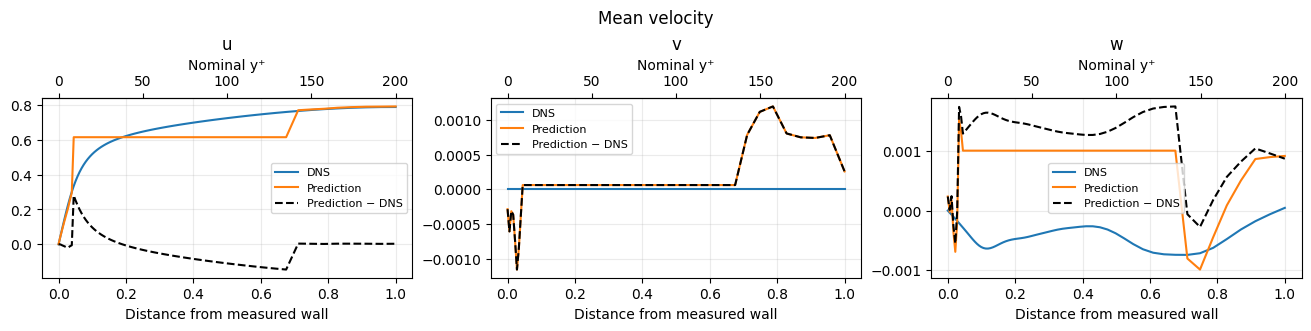

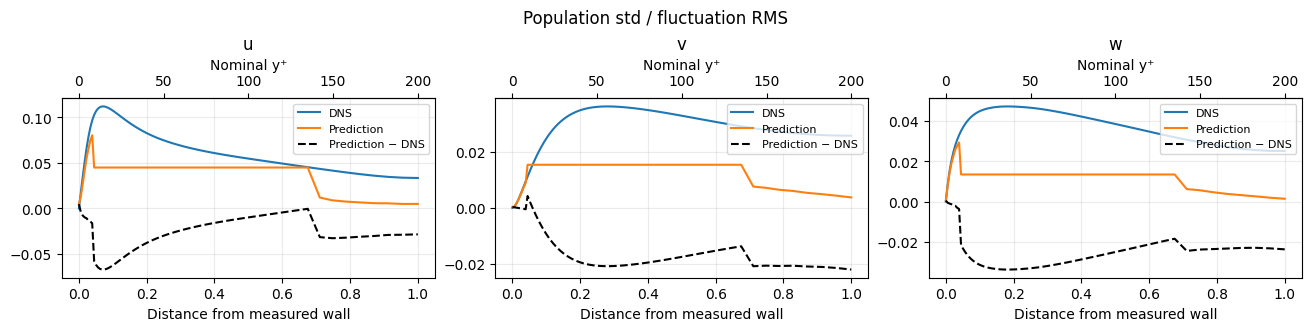

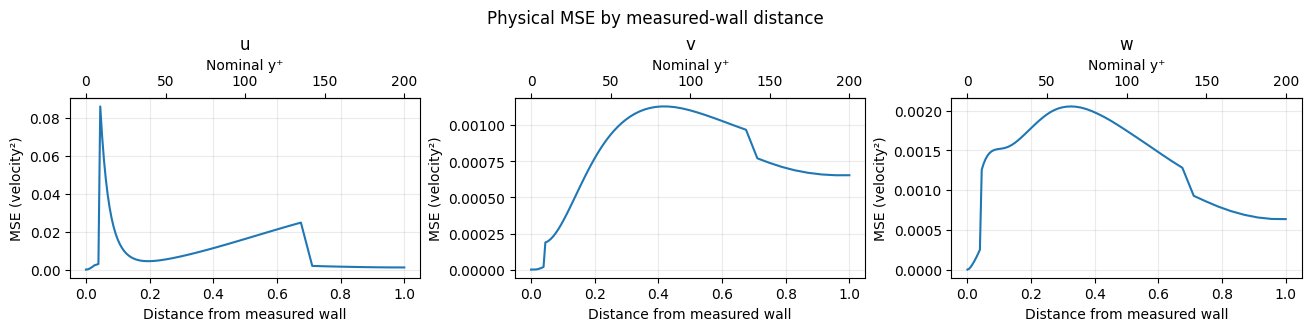

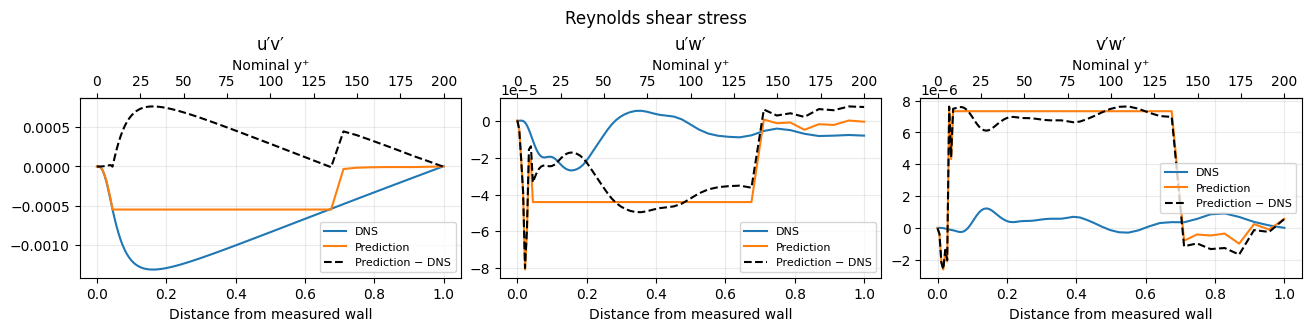

all: 65 planes; DC paired MSE (u,v,w): [8.65144497e-03 2.48169523e-07 6.14882895e-06]
Viscous sublayer: 5 planes; DC paired MSE (u,v,w): [8.37512067e-05 2.47866455e-07 3.79992075e-07]
Buffer layer: 20 planes; DC paired MSE (u,v,w): [1.85573053e-02 2.25334417e-07 6.62169148e-06]
Nominal log/overlap: 26 planes; DC paired MSE (u,v,w): [3.40726807e-03 1.34202765e-07 8.06235235e-06]
Outer/core: 14 planes; DC paired MSE (u,v,w): [7.29929220e-03 4.92551891e-07 3.97992361e-06]


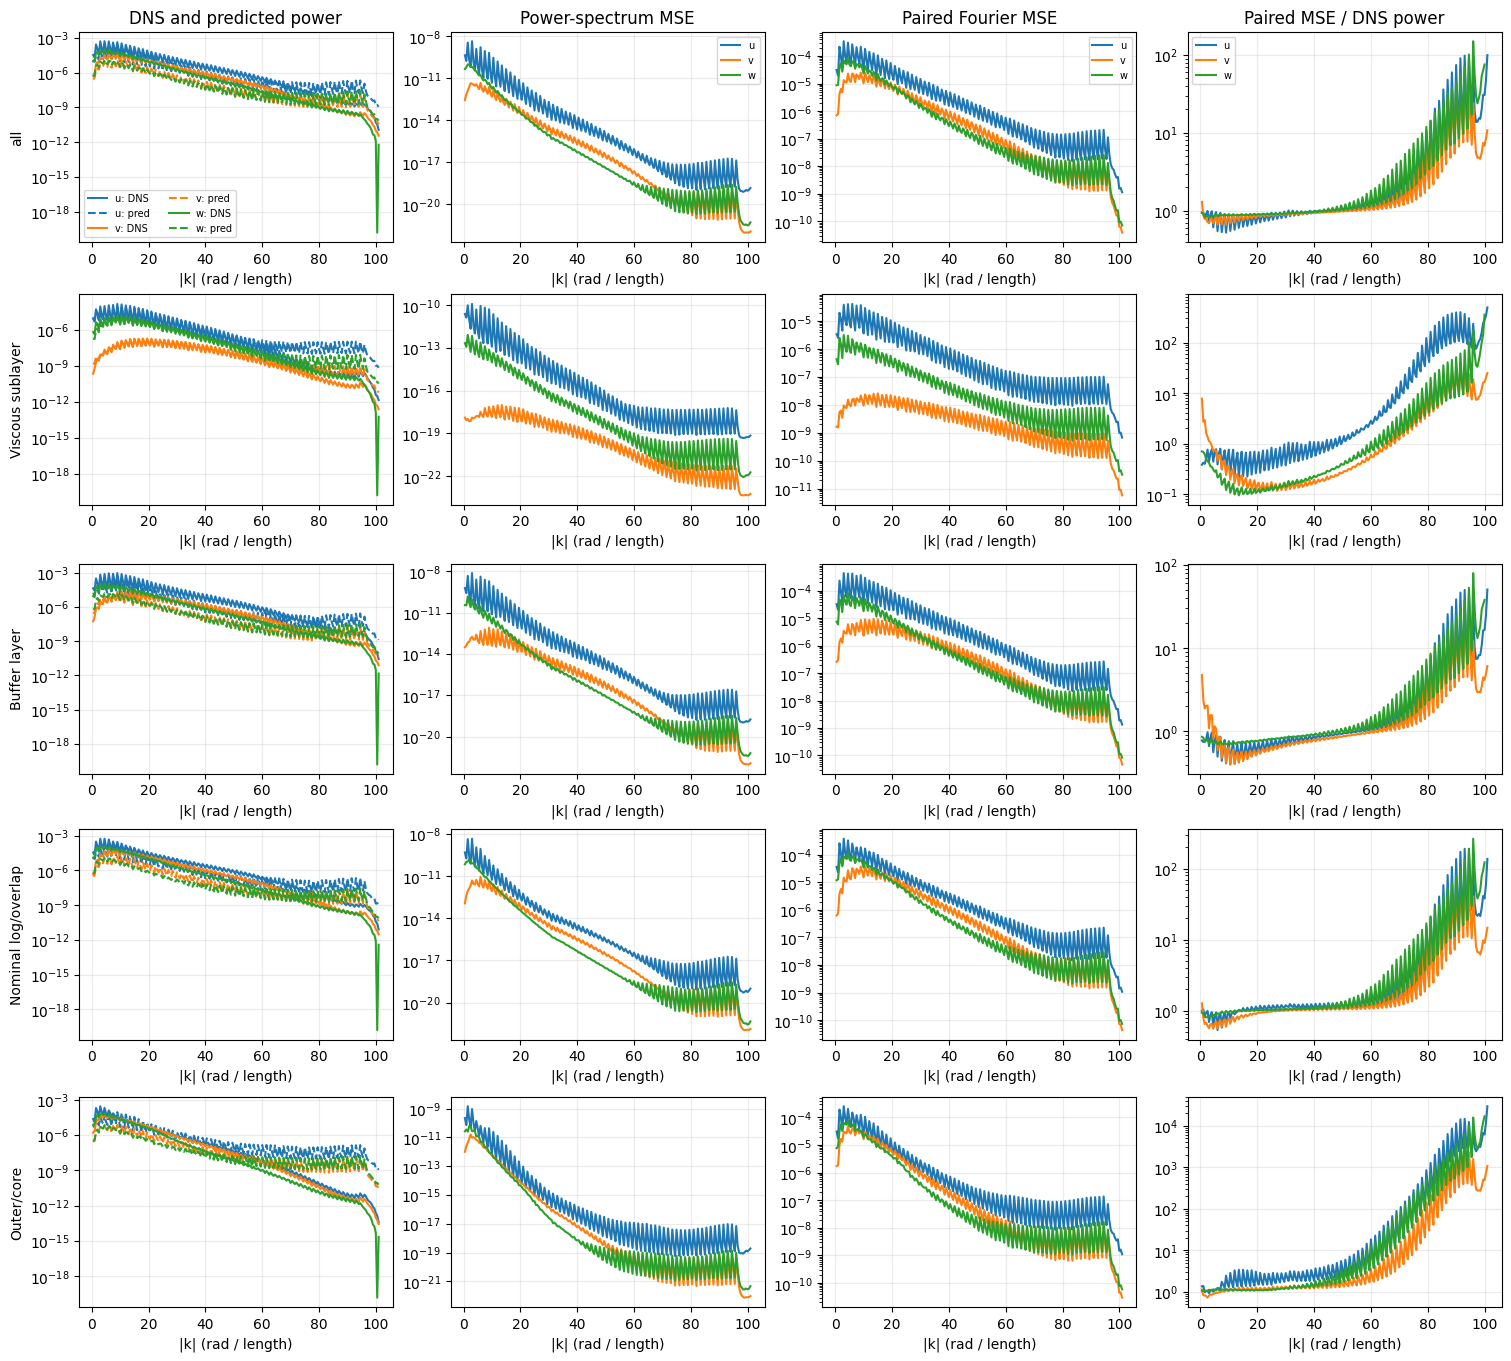

u skew, excess kurtosis (prediction / DNS): [[-0.37675052849418467, -0.2793191875196541], [-0.15551822956624312, -0.7676263428783408]]
v skew, excess kurtosis (prediction / DNS): [[-0.10894899173147315, 0.10050371223061072], [-0.26196148306438694, 2.8637350728037347]]
w skew, excess kurtosis (prediction / DNS): [[-0.061521029225673284, 0.28493021218935644], [0.003991804099079759, 0.4731013865028362]]


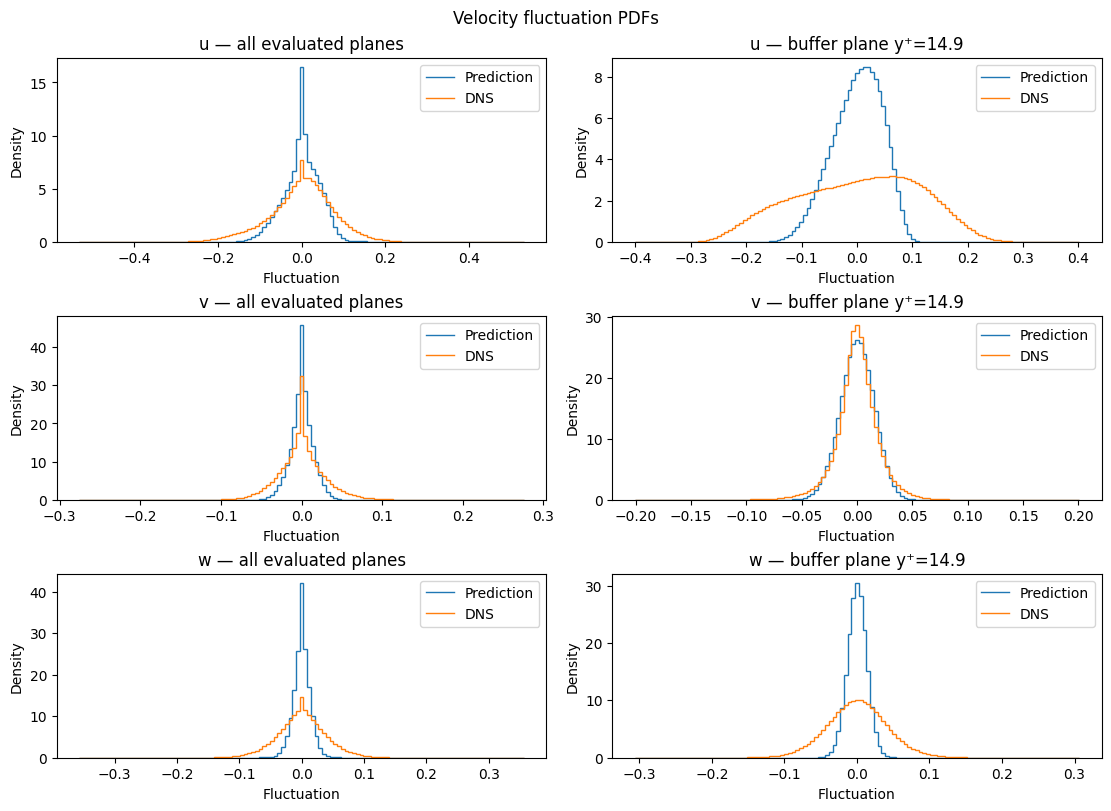

In [6]:
if results is not None:
    plot_results(results,y,yp,grid,pdf_plane)